### Import Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
pd.set_option("display.max_columns", None)
import numpy as np
import matplotlib.pyplot as plt
from lib_file import lib_path
import os
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
import joblib


### Data Loading

In [2]:
df = pd.read_csv("extracted_features.csv")
df = df.sample(frac=1).reset_index(drop=True)
df.head()

,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_14,column_15,column_16,column_17,column_18,column_19,column_20,column_21,column_22,column_23,column_24,column_25,column_26,column_27,column_28,column_29,column_30,column_31,column_32,column_33,column_34,column_35,column_36,column_37,column_38,column_39,column_40,column_41,column_42,column_43,column_44,column_45,column_46,column_47,column_48,column_49,column_50,column_51,column_52,column_53,column_54,column_55,column_56,column_57,column_58,column_59,column_60,column_61,column_62,column_63,column_64,column_65,column_66,column_67,column_68,column_69,column_70,column_71,column_72,column_73,column_74,column_75,column_76,column_77,column_78,column_79,column_80,column_81,column_82,column_83,column_84,column_85,column_86,column_87,column_88,column_89,column_90,column_91,column_92,column_93,column_94,column_95,column_96,column_97,column_98,column_99,column_100,column_101,column_102,column_103,column_104,column_105,column_106,column_107,column_108,column_109,column_110,column_111,column_112,column_113,column_114,column_115,column_116,column_117,column_118,column_119,column_120,column_121,column_122,column_123,column_124,column_125,column_126,column_127,column_128,column_129,column_130,column_131,column_132,column_133,column_134,column_135,column_136,column_137,column_138,column_139,column_140,column_141,column_142,column_143,column_144,column_145,column_146,column_147,column_148,column_149,column_150,column_151,column_152,column_153,column_154,column_155,column_156,column_157,column_158,column_159,column_160,column_161,column_162,column_163,column_164,column_165,column_166,column_167,column_168,column_169,column_170,column_171,column_172,column_173,column_174,column_175,column_176,column_177,column_178,column_179,column_180,column_181,column_182,column_183,column_184,column_185,column_186,column_187,column_188,column_189,column_190,column_191,column_192,column_193,column_194,column_195,column_196,column_197,column_198,column_199,column_200,column_201,column_202,column_203,column_204,column_205,column_206,column_207,column_208,column_209,column_210,column_211,column_212,column_213,column_214,column_215,column_216,column_217,column_218,column_219,column_220,column_221,column_222,column_223,column_224,column_225,column_226,column_227,column_228,column_229,column_230,column_231,column_232,column_233,column_234,column_235,column_236,column_237,column_238,column_239,column_240,column_241,column_242,column_243,column_244,column_245,column_246,column_247,column_248,column_249,column_250,column_251,column_252,column_253,column_254,column_255,column_256,column_257,column_258,column_259,column_260,column_261,column_262,column_263,column_264,column_265,column_266,column_267,column_268,column_269,column_270,column_271,column_272,column_273,column_274,column_275,column_276,column_277,column_278,column_279,column_280,column_281,column_282,column_283,column_284,column_285,column_286,column_287,column_288,column_289,column_290,column_291,column_292,column_293,column_294,column_295,column_296,column_297,column_298,column_299,column_300,column_301,column_302,column_303,column_304,column_305,column_306,column_307,column_308,column_309,column_310,column_311,column_312,column_313,column_314,column_315,column_316,column_317,column_318,column_319,column_320,column_321,column_322,column_323,column_324,column_325,column_326,column_327,column_328,column_329,column_330,column_331,column_332,column_333,column_334,column_335,column_336,column_337,column_338,column_339,column_340,column_341,column_342,column_343,column_344,column_345,column_346,column_347,column_348,column_349,column_350,column_351,column_352,column_353,column_354,column_355,column_356,column_357,column_358,column_359,column_360,column_361,column_362,column_363,column_364,column_365,column_366,column_367,column_368,column_369,column_370,column_371,column_372,column_373,colu

### Data Preprocessing

In [3]:
df['target'].value_counts()

target
negative    21852
positive    21407
Name: count, dtype: int64

In [4]:
class_labels = df['target'].unique().tolist()
class_labels.sort()

In [5]:
dict_1 = {"positive":0, "negative":1}
df['target'] = df['target'].map(dict_1)

In [6]:
X = df.iloc[:, :-1]
X.head()

,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_14,column_15,column_16,column_17,column_18,column_19,column_20,column_21,column_22,column_23,column_24,column_25,column_26,column_27,column_28,column_29,column_30,column_31,column_32,column_33,column_34,column_35,column_36,column_37,column_38,column_39,column_40,column_41,column_42,column_43,column_44,column_45,column_46,column_47,column_48,column_49,column_50,column_51,column_52,column_53,column_54,column_55,column_56,column_57,column_58,column_59,column_60,column_61,column_62,column_63,column_64,column_65,column_66,column_67,column_68,column_69,column_70,column_71,column_72,column_73,column_74,column_75,column_76,column_77,column_78,column_79,column_80,column_81,column_82,column_83,column_84,column_85,column_86,column_87,column_88,column_89,column_90,column_91,column_92,column_93,column_94,column_95,column_96,column_97,column_98,column_99,column_100,column_101,column_102,column_103,column_104,column_105,column_106,column_107,column_108,column_109,column_110,column_111,column_112,column_113,column_114,column_115,column_116,column_117,column_118,column_119,column_120,column_121,column_122,column_123,column_124,column_125,column_126,column_127,column_128,column_129,column_130,column_131,column_132,column_133,column_134,column_135,column_136,column_137,column_138,column_139,column_140,column_141,column_142,column_143,column_144,column_145,column_146,column_147,column_148,column_149,column_150,column_151,column_152,column_153,column_154,column_155,column_156,column_157,column_158,column_159,column_160,column_161,column_162,column_163,column_164,column_165,column_166,column_167,column_168,column_169,column_170,column_171,column_172,column_173,column_174,column_175,column_176,column_177,column_178,column_179,column_180,column_181,column_182,column_183,column_184,column_185,column_186,column_187,column_188,column_189,column_190,column_191,column_192,column_193,column_194,column_195,column_196,column_197,column_198,column_199,column_200,column_201,column_202,column_203,column_204,column_205,column_206,column_207,column_208,column_209,column_210,column_211,column_212,column_213,column_214,column_215,column_216,column_217,column_218,column_219,column_220,column_221,column_222,column_223,column_224,column_225,column_226,column_227,column_228,column_229,column_230,column_231,column_232,column_233,column_234,column_235,column_236,column_237,column_238,column_239,column_240,column_241,column_242,column_243,column_244,column_245,column_246,column_247,column_248,column_249,column_250,column_251,column_252,column_253,column_254,column_255,column_256,column_257,column_258,column_259,column_260,column_261,column_262,column_263,column_264,column_265,column_266,column_267,column_268,column_269,column_270,column_271,column_272,column_273,column_274,column_275,column_276,column_277,column_278,column_279,column_280,column_281,column_282,column_283,column_284,column_285,column_286,column_287,column_288,column_289,column_290,column_291,column_292,column_293,column_294,column_295,column_296,column_297,column_298,column_299,column_300,column_301,column_302,column_303,column_304,column_305,column_306,column_307,column_308,column_309,column_310,column_311,column_312,column_313,column_314,column_315,column_316,column_317,column_318,column_319,column_320,column_321,column_322,column_323,column_324,column_325,column_326,column_327,column_328,column_329,column_330,column_331,column_332,column_333,column_334,column_335,column_336,column_337,column_338,column_339,column_340,column_341,column_342,column_343,column_344,column_345,column_346,column_347,column_348,column_349,column_350,column_351,column_352,column_353,column_354,column_355,column_356,column_357,column_358,column_359,column_360,column_361,column_362,column_363,column_364,column_365,column_366,column_367,column_368,column_369,column_370,column_371,column_372,column_373,colu

In [7]:
y = df.iloc[:, -1:]
y.head()

,target
0,1
1,0
2,1
3,1
4,0


### Data Splitting

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True, stratify=y)
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(34607, 768) (8652, 768) (34607, 1) (8652, 1)


## Model-1 SVC

In [9]:
from sklearn.svm import SVC

In [10]:
svc_model = SVC()
svc_model.fit(X_train, y_train)

SVC()

In [11]:
y_pred = svc_model.predict(X_test)

In [12]:
y_pred[:20]

array([1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1],
      dtype=int64)

In [14]:
acc_svc = accuracy_score(y_test, y_pred) * 100

In [15]:
print(f"SVC Model Accuracy: {acc_svc:.2f}%")

SVC Model Accuracy: 72.55%


In [16]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.74      0.69      0.71      4281
           1       0.71      0.76      0.74      4371

    accuracy                           0.73      8652
   macro avg       0.73      0.73      0.72      8652
weighted avg       0.73      0.73      0.73      8652



In [18]:
def plot_confusion_matrix(y_true, y_pred, labels, model_name="Model"):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels,annot_kws={"size": 28})
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.tight_layout()
    plt.show()

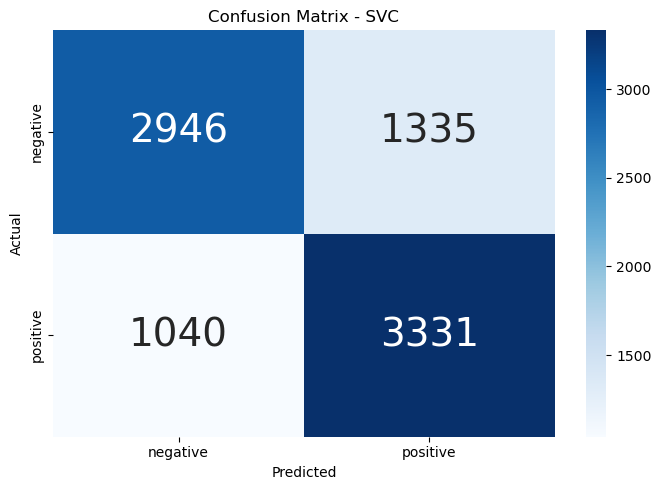

In [19]:
plot_confusion_matrix(y_test, y_pred, labels=class_labels, model_name="SVC")

In [22]:
joblib.dump(svc_model, "models/svc_model.pkl")

['models/svc_model.pkl']

## Model-2: LogisticRegression

In [9]:
from sklearn.linear_model import LogisticRegression

In [10]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [11]:
y_pred = lr_model.predict(X_test)

In [12]:
y_pred[:50]

array([1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 1, 0, 1], dtype=int64)

In [13]:
acc_lr = accuracy_score(y_test, y_pred) * 100

In [14]:
print(f"LogisticRegression Accuracy: {acc_lr:.2f}%")

LogisticRegression Accuracy: 85.02%


In [15]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      4281
           1       0.85      0.85      0.85      4371

    accuracy                           0.85      8652
   macro avg       0.85      0.85      0.85      8652
weighted avg       0.85      0.85      0.85      8652



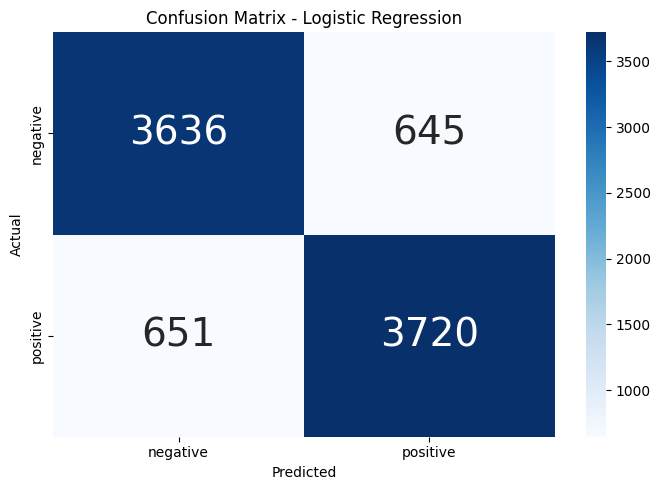

In [20]:
plot_confusion_matrix(y_test, y_pred, labels=class_labels, model_name="Logistic Regression")

In [21]:
joblib.dump(lr_model, "models/lr_model.pkl")

['models/lr_model.pkl']

---

In [9]:
from tensorflow.keras.utils import to_categorical
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout

In [10]:
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

In [11]:
y_test

array([[1., 0.],
       [0., 1.],
       [1., 0.],
       ...,
       [0., 1.],
       [0., 1.],
       [0., 1.]], dtype=float32)

***Reshape for RNN***

In [12]:
X_train_rnn = np.reshape(X_train.values, (X_train.shape[0], X_train.shape[1], 1))
X_test_rnn = np.reshape(X_test.values, (X_test.shape[0], X_test.shape[1], 1))

print(X_train_rnn.shape, X_test_rnn.shape)

(34607, 768, 1) (8652, 768, 1)



### Build RNN Model 

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.optimizers import Adam

model = Sequential()

# Layer 1
model.add(SimpleRNN(64, return_sequences=True, input_shape=(X_train_rnn.shape[1], 1)))
model.add(Dropout(0.3))

# Layer 2
model.add(SimpleRNN(32))
model.add(Dropout(0.3))

# Dense Layer (IMPORTANT ADDITION)
model.add(Dense(16, activation='relu'))
model.add(Dropout(0.2))

# Output Layer
model.add(Dense(2, activation='softmax'))

# Compile (lower learning rate = more stable)
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [15]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn (SimpleRNN)      (None, 768, 64)           4224      
                                                                 
 dropout (Dropout)           (None, 768, 64)           0         
                                                                 
 simple_rnn_1 (SimpleRNN)    (None, 32)                3104      
                                                                 
 dropout_1 (Dropout)         (None, 32)                0         
                                                                 
 dense (Dense)               (None, 16)                528       
                                                                 
 dropout_2 (Dropout)         (None, 16)                0         
                                                                 
 dense_1 (Dense)             (None, 2)                 3

***Train***

In [16]:
history=model.fit(
    X_train_rnn,
    y_train,
    validation_data=(X_test_rnn, y_test),
    epochs=10,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/10
1082/1082 [==============================] - 247s 227ms/step - loss: 0.6971 - accuracy: 0.5066 - val_loss: 0.6929 - val_accuracy: 0.5054
Epoch 2/10
1082/1082 [==============================] - 231s 214ms/step - loss: 0.6930 - accuracy: 0.5108 - val_loss: 0.6928 - val_accuracy: 0.5054
Epoch 3/10
1082/1082 [==============================] - 234s 216ms/step - loss: 0.6890 - accuracy: 0.5335 - val_loss: 0.6482 - val_accuracy: 0.6390
Epoch 4/10
1082/1082 [==============================] - 238s 220ms/step - loss: 0.6534 - accuracy: 0.6259 - val_loss: 0.6143 - val_accuracy: 0.6764
Epoch 5/10
1082/1082 [==============================] - 237s 219ms/step - loss: 0.6061 - accuracy: 0.6843 - val_loss: 0.5674 - val_accuracy: 0.7037
Epoch 6/10
1082/1082 [==============================] - 241s 223ms/step - loss: 0.5719 - accuracy: 0.7103 - val_loss: 0.5458 - val_accuracy: 0.7235
Epoch 7/10
1082/1082 [==============================] - 239s 221ms/step - loss: 0.5444 - accuracy: 0.7330 - val_

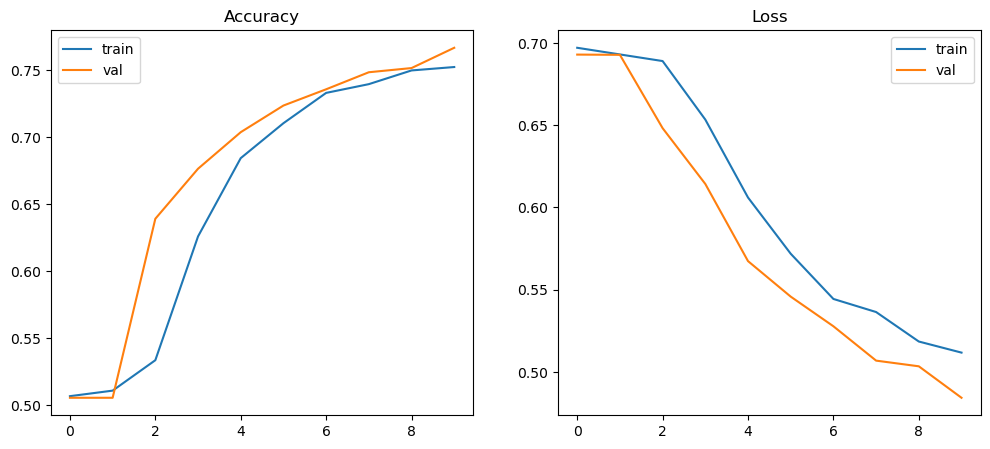

In [17]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title("Loss")
plt.legend()

plt.show()

In [18]:
pred_probs = model.predict(X_test_rnn)

y_pred = np.argmax(pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

In [19]:
pred_probs

array([[0.43370828, 0.56629175],
       [0.08755513, 0.91244495],
       [0.90171677, 0.09828325],
       ...,
       [0.6309994 , 0.36900058],
       [0.44280237, 0.5571977 ],
       [0.05513523, 0.9448648 ]], dtype=float32)

### EVALUATION


In [20]:
acc = accuracy_score(y_true, y_pred)
print(f"RNN Model Accuracy: {acc*100:.2f}%")

RNN Model Accuracy: 76.66%


In [21]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.77      0.75      0.76      4281
           1       0.76      0.78      0.77      4371

    accuracy                           0.77      8652
   macro avg       0.77      0.77      0.77      8652
weighted avg       0.77      0.77      0.77      8652



In [25]:
import numpy as np

y_test_labels = np.argmax(y_test, axis=1)

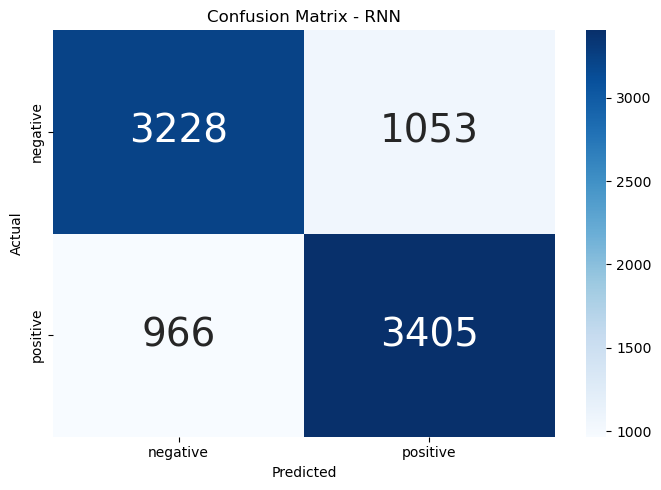

In [27]:
plot_confusion_matrix(y_test_labels, y_pred, labels=class_labels, model_name="RNN")

# Thank You